<a href="https://colab.research.google.com/github/ayushidhete/data-mining-assignment-2/blob/main/submissions/Book_Crossing_Recommendation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
!pip install pandas numpy scipy scikit-learn pyarrow matplotlib seaborn

In [28]:
import pandas as pd
import numpy as np
import os
import zipfile
import urllib.request
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

print("Libraries imported successfully!")

Libraries imported successfully!


In [29]:
os.makedirs("bronze", exist_ok=True)
os.makedirs("silver", exist_ok=True)
os.makedirs("gold", exist_ok=True)

print("Data lake folders created!")

Data lake folders created!


In [30]:
import requests
import zipfile
import os

url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=60
)

print("Status code:", response.status_code)

response.raise_for_status()

with open("book-crossings.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("book-crossings.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset downloaded and extracted successfully!")

Status code: 200
Dataset downloaded and extracted successfully!


In [31]:
print(os.listdir("dataset"))

['BX-Book-Ratings.csv', 'BX-Users.csv', 'BX-Books.csv']


In [32]:
users = pd.read_csv(
    "dataset/BX-Users.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False
)

books = pd.read_csv(
    "dataset/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False,
    on_bad_lines="warn"
)

ratings = pd.read_csv(
    "dataset/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False
)

print("All three datasets loaded!")

/tmp/ipykernel_1828/1535010911.py:8: ParserWarning: Skipping line 6452: expected 8 fields, saw 9
Skipping line 43667: expected 8 fields, saw 10
Skipping line 51751: expected 8 fields, saw 9
Skipping line 92038: expected 8 fields, saw 9
Skipping line 104319: expected 8 fields, saw 9
Skipping line 121768: expected 8 fields, saw 9
Skipping line 144058: expected 8 fields, saw 9
Skipping line 150789: expected 8 fields, saw 9
Skipping line 157128: expected 8 fields, saw 9
Skipping line 180189: expected 8 fields, saw 9
Skipping line 185738: expected 8 fields, saw 9
Skipping line 209388: expected 8 fields, saw 9
Skipping line 220626: expected 8 fields, saw 9
Skipping line 227933: expected 8 fields, saw 11
Skipping line 228957: expected 8 fields, saw 10
Skipping line 245933: expected 8 fields, saw 9
Skipping line 251296: expected 8 fields, saw 9
Skipping line 259941: expected 8 fields, saw 9
Skipping line 261529: expected 8 fields, saw 9

  books = pd.read_csv(


All three datasets loaded!


In [33]:
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

print("\nBook columns:")
print(books.columns.tolist())

print("\nFirst 5 books:")
display(books.head())

Users: (278858, 3)
Books: (271360, 8)
Ratings: (1149780, 3)

Book columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']

First 5 books:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [34]:
with open("dataset/BX-Books.csv", encoding="latin-1") as f:
    for line_no, line in enumerate(f, start=1):
        if line_no in [6452, 6453]:
            print("Line:", line_no)
            print(line)

Line: 6452
"0735201994";"Peterman Rides Again: Adventures Continue with the Real \"J. Peterman\" Through Life &amp; the Catalog Business";"John Peterman";"2000";"Prentice Hall Art";"http://images.amazon.com/images/P/0735201994.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0735201994.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0735201994.01.LZZZZZZZ.jpg"

Line: 6453
"1414011458";"No More Bobs";"Cynthia Borris";"2003";"Authorhouse";"http://images.amazon.com/images/P/1414011458.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/1414011458.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/1414011458.01.LZZZZZZZ.jpg"



In [35]:
users = pd.read_csv(
    "dataset/BX-Users.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False
)

books = pd.read_csv(
    "dataset/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False,
    escapechar="\\"
)

ratings = pd.read_csv(
    "dataset/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False
)

print("All datasets loaded successfully!")

print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

All datasets loaded successfully!
Users: (278858, 3)
Books: (271379, 8)
Ratings: (1149780, 3)


In [36]:
print(
    books[
        books["ISBN"] == "0735201994"
    ]["Book-Title"]
)

6450    Peterman Rides Again: Adventures Continue with...
Name: Book-Title, dtype: object


In [37]:
from datetime import datetime, timezone

timestamp = datetime.now(timezone.utc)

users["ingestion_timestamp"] = timestamp
books["ingestion_timestamp"] = timestamp
ratings["ingestion_timestamp"] = timestamp

users.to_parquet("bronze/users.parquet", index=False)
books.to_parquet("bronze/books.parquet", index=False)
ratings.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze layer created successfully!")

Bronze layer created successfully!


In [38]:
print(os.listdir("bronze"))

for file in os.listdir("bronze"):
    df = pd.read_parquet("bronze/" + file)
    print(file, df.shape)

['ratings.parquet', 'users.parquet', 'books.parquet']
ratings.parquet (1149780, 4)
users.parquet (278858, 4)
books.parquet (271379, 9)


In [39]:
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze data loaded successfully!")

Bronze data loaded successfully!


In [40]:
print("Users shape:", users.shape)
print("Books shape:", books.shape)
print("Ratings shape:", ratings.shape)

Users shape: (278858, 4)
Books shape: (271379, 9)
Ratings shape: (1149780, 4)


In [41]:
print("USERS DATA TYPES")
print(users.dtypes)

print("\nBOOKS DATA TYPES")
print(books.dtypes)

print("\nRATINGS DATA TYPES")
print(ratings.dtypes)

USERS DATA TYPES
User-ID                              int64
Location                            object
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object

BOOKS DATA TYPES
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                  int64
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

RATINGS DATA TYPES
User-ID                              int64
ISBN                                object
Book-Rating                          int64
ingestion_timestamp    datetime64[us, UTC]
dtype: object


In [42]:
print("USERS MISSING VALUES")
print(users.isnull().sum())

print("\nBOOKS MISSING VALUES")
print(books.isnull().sum())

print("\nRATINGS MISSING VALUES")
print(ratings.isnull().sum())

USERS MISSING VALUES
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

BOOKS MISSING VALUES
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0
dtype: int64

RATINGS MISSING VALUES
User-ID                0
ISBN                   0
Book-Rating            0
ingestion_timestamp    0
dtype: int64


Rating distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Number of zero ratings: 716109


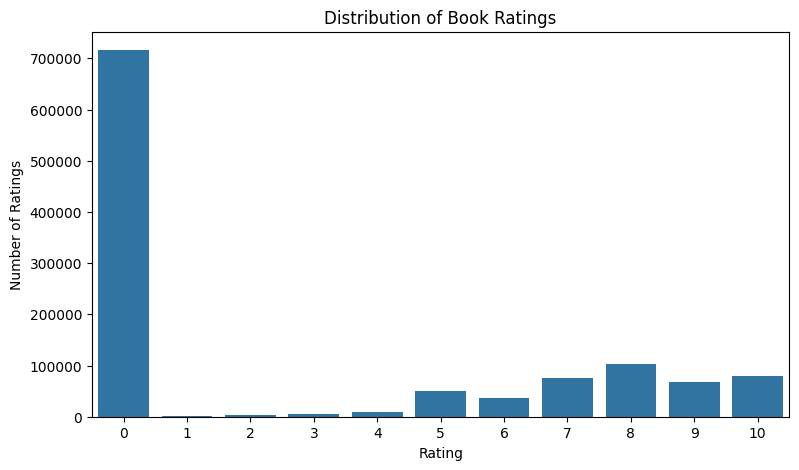

In [43]:
print("Rating distribution:")
print(ratings["Book-Rating"].value_counts().sort_index())

print("\nNumber of zero ratings:",
      (ratings["Book-Rating"] == 0).sum())

plt.figure(figsize=(9, 5))
sns.countplot(data=ratings, x="Book-Rating")
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64


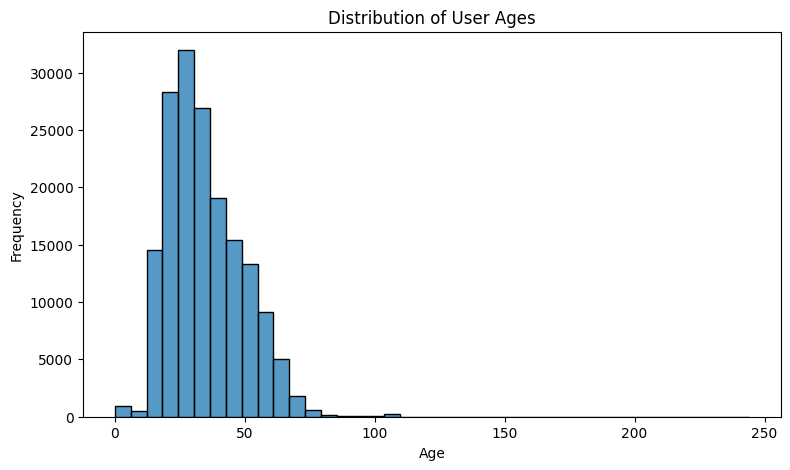

Ages below 5: 882
Ages above 100: 366


In [44]:
print(users["Age"].describe())

plt.figure(figsize=(9, 5))
sns.histplot(users["Age"].dropna(), bins=40)
plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

print("Ages below 5:", (users["Age"] < 5).sum())
print("Ages above 100:", (users["Age"] > 100).sum())

count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Year 0 count: 4619
Future year count: 11


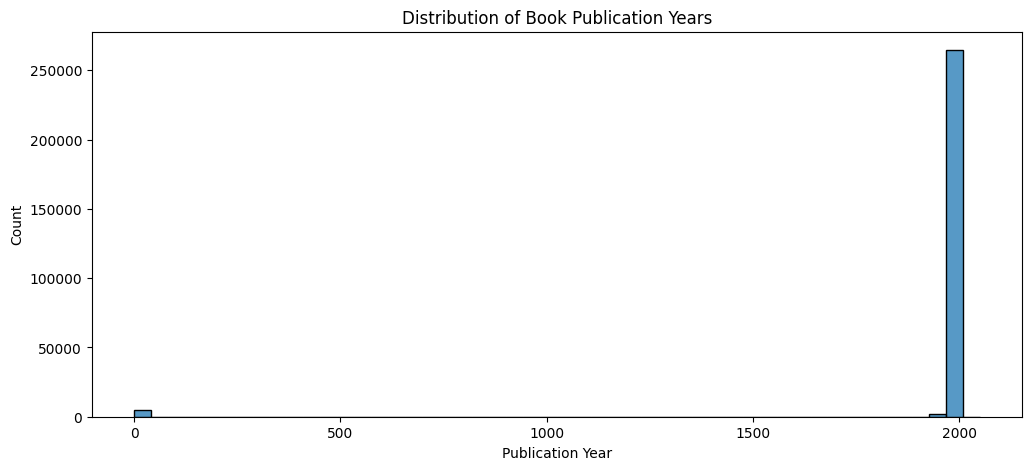

In [45]:
books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

print(books["Year-Of-Publication"].describe())

print("Year 0 count:",
      (books["Year-Of-Publication"] == 0).sum())

print("Future year count:",
      (books["Year-Of-Publication"] > 2026).sum())

plt.figure(figsize=(12, 5))
sns.histplot(
    books["Year-Of-Publication"].dropna(),
    bins=50
)
plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.show()

In [46]:
ratings_per_user = ratings.groupby("User-ID").size()

ratings_per_book = ratings.groupby("ISBN").size()

print("Ratings per user:")
print(ratings_per_user.describe())

print("\nRatings per book:")
print(ratings_per_book.describe())

print("\nUsers with fewer than 10 ratings:",
      (ratings_per_user < 10).sum())

print("Books with fewer than 10 ratings:",
      (ratings_per_book < 10).sum())

Ratings per user:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64

Users with fewer than 10 ratings: 92186
Books with fewer than 10 ratings: 322237


In [47]:
total_users = ratings["User-ID"].nunique()
total_books = ratings["ISBN"].nunique()

possible_pairs = total_users * total_books

actual_pairs = ratings.drop_duplicates(
    subset=["User-ID", "ISBN"]
).shape[0]

sparsity = (
    1 - actual_pairs / possible_pairs
) * 100

print("Total users:", total_users)
print("Total books:", total_books)
print("Possible user-book pairs:", possible_pairs)
print("Actual rated pairs:", actual_pairs)
print("Matrix sparsity:", round(sparsity, 2), "%")

Total users: 105283
Total books: 340556
Possible user-book pairs: 35854757348
Actual rated pairs: 1149780
Matrix sparsity: 100.0 %


### EDA Observations

1. Dataset shapes:
   Users: [value], Books: [value], Ratings: [value].

2. Data types and missing values:
   Some columns contain missing values and require cleaning.

3. Rating distribution:
   Ratings range from 0 to 10. Zero ratings will be removed.

4. User age distribution:
   Invalid ages below 5 and above 100 will be replaced with null
   and missing values will be filled with the median.

5. Publication year:
   Zero and future publication years will be replaced with null.

6. Ratings per user and book:
   Many users and books have fewer than 10 ratings.
   A minimum threshold of 10 ratings will be applied.

7. Matrix sparsity:
   The rating matrix is highly sparse, so a sparse matrix
   representation will be used in the Gold layer.

In [50]:
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

users = users.copy()
books = books.copy()
ratings = ratings.copy()

print("Bronze data loaded for cleaning!")

Bronze data loaded for cleaning!


In [49]:
print("Duplicates before cleaning:")
print("Users:", users.duplicated().sum())
print("Books:", books.duplicated().sum())
print("Ratings:", ratings.duplicated().sum())

users = users.drop_duplicates()
books = books.drop_duplicates()
ratings = ratings.drop_duplicates()

# Keep only one record per User-ID and ISBN
users = users.drop_duplicates(subset=["User-ID"], keep="first")
books = books.drop_duplicates(subset=["ISBN"], keep="first")

print("\nDuplicates removed!")

Duplicates before cleaning:
Users: 0
Books: 0
Ratings: 0

Duplicates removed!


In [48]:
ratings["Book-Rating"] = pd.to_numeric(
    ratings["Book-Rating"],
    errors="coerce"
)

ratings = ratings[
    ratings["Book-Rating"].between(1, 10)
].copy()

print("Ratings after cleaning:", ratings.shape)
print("Remaining zero ratings:",
      (ratings["Book-Rating"] == 0).sum())

Ratings after cleaning: (433671, 4)
Remaining zero ratings: 0


In [51]:
users["Age"] = pd.to_numeric(
    users["Age"],
    errors="coerce"
)

users.loc[
    (users["Age"] < 5) | (users["Age"] > 100),
    "Age"
] = np.nan

median_age = users["Age"].median()

users["Age"] = users["Age"].fillna(median_age)

print("Median age:", median_age)
print("Missing ages remaining:", users["Age"].isnull().sum())

Median age: 32.0
Missing ages remaining: 0


In [52]:
location_parts = (
    users["Location"]
    .fillna("")
    .astype(str)
    .str.split(",", n=2, expand=True)
)

location_parts = location_parts.reindex(columns=[0, 1, 2])

users["City"] = location_parts[0].str.strip().str.title()
users["State"] = location_parts[1].str.strip().str.title()
users["Country"] = location_parts[2].str.strip().str.title()

users.drop(columns=["Location"], inplace=True)

print(users[["City", "State", "Country"]].head())

          City            State         Country
0          Nyc         New York             Usa
1     Stockton       California             Usa
2       Moscow  Yukon Territory          Russia
3        Porto         V.N.Gaia        Portugal
4  Farnborough            Hants  United Kingdom


In [53]:
books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

current_year = 2026

books.loc[
    (books["Year-Of-Publication"] == 0) |
    (books["Year-Of-Publication"] > current_year),
    "Year-Of-Publication"
] = np.nan

print("Invalid publication years remaining:",
      ((books["Year-Of-Publication"] == 0) |
       (books["Year-Of-Publication"] > current_year)).sum())

Invalid publication years remaining: 0


In [54]:
text_columns = [
    "Book-Title",
    "Book-Author",
    "Publisher"
]

for col in text_columns:
    books[col] = (
        books[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.title()
    )

for col in ["City", "State", "Country"]:
    users[col] = (
        users[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.title()
    )

print("Text cleaning completed!")

Text cleaning completed!


In [55]:
image_columns = [
    "Image-URL-S",
    "Image-URL-M",
    "Image-URL-L"
]

books.drop(
    columns=image_columns,
    inplace=True,
    errors="ignore"
)

print("Remaining book columns:")
print(books.columns.tolist())

Remaining book columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'ingestion_timestamp']


In [56]:
ratings = ratings[
    ratings["User-ID"].isin(users["User-ID"]) &
    ratings["ISBN"].isin(books["ISBN"])
].copy()

print("Valid ratings:", ratings.shape)

Valid ratings: (1031175, 4)


In [57]:
min_ratings = 10

while True:

    old_count = len(ratings)

    user_counts = ratings.groupby("User-ID").size()
    book_counts = ratings.groupby("ISBN").size()

    valid_users = user_counts[
        user_counts >= min_ratings
    ].index

    valid_books = book_counts[
        book_counts >= min_ratings
    ].index

    ratings = ratings[
        ratings["User-ID"].isin(valid_users) &
        ratings["ISBN"].isin(valid_books)
    ].copy()

    if len(ratings) == old_count:
        break

users = users[
    users["User-ID"].isin(ratings["User-ID"])
].copy()

books = books[
    books["ISBN"].isin(ratings["ISBN"])
].copy()

print("Threshold filtering completed!")
print("Users remaining:", len(users))
print("Books remaining:", len(books))
print("Ratings remaining:", len(ratings))

Threshold filtering completed!
Users remaining: 6605
Books remaining: 13228
Ratings remaining: 365894


In [58]:
users.to_parquet("silver/users.parquet", index=False)

books.to_parquet("silver/books.parquet", index=False)

ratings.to_parquet("silver/ratings.parquet", index=False)

print("Silver layer saved successfully!")

Silver layer saved successfully!


In [59]:
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

print("\nSilver files:")
print(os.listdir("silver"))

Users: (6605, 6)
Books: (13228, 6)
Ratings: (365894, 4)

Silver files:
['ratings.parquet', 'users.parquet', 'books.parquet']


In [60]:
users = pd.read_parquet("silver/users.parquet")
books = pd.read_parquet("silver/books.parquet")
ratings = pd.read_parquet("silver/ratings.parquet")

# Keep ISBN consistent across all tables
books["ISBN"] = books["ISBN"].astype(str)
ratings["ISBN"] = ratings["ISBN"].astype(str)

print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

Users: (6605, 6)
Books: (13228, 6)
Ratings: (365894, 4)


In [61]:
user_ids = ratings["User-ID"].drop_duplicates().to_numpy()
book_ids = ratings["ISBN"].drop_duplicates().to_numpy()

user_to_index = {user_id: i for i, user_id in enumerate(user_ids)}
book_to_index = {book_id: i for i, book_id in enumerate(book_ids)}

print("Unique users:", len(user_ids))
print("Unique books:", len(book_ids))

Unique users: 6605
Unique books: 13228


In [62]:
from scipy.sparse import csr_matrix, save_npz

row = ratings["ISBN"].map(book_to_index).to_numpy()
col = ratings["User-ID"].map(user_to_index).to_numpy()
data = ratings["Book-Rating"].to_numpy(dtype=float)

rating_matrix = csr_matrix(
    (data, (row, col)),
    shape=(len(book_ids), len(user_ids))
)

print("Matrix shape:", rating_matrix.shape)
print("Non-zero ratings:", rating_matrix.nnz)

Matrix shape: (13228, 6605)
Non-zero ratings: 365894


In [63]:
save_npz("gold/rating_matrix.npz", rating_matrix)

pd.DataFrame({"User-ID": user_ids}).to_csv(
    "gold/user_ids.csv", index=False
)

pd.DataFrame({"ISBN": book_ids}).to_csv(
    "gold/book_ids.csv", index=False
)

print("Rating matrix and mappings saved!")

Rating matrix and mappings saved!


In [64]:
book_lookup = books[
    ["ISBN", "Book-Title", "Book-Author"]
].drop_duplicates(subset=["ISBN"])

book_lookup.to_csv("gold/book_lookup.csv", index=False)

book_lookup.head()

,ISBN,Book-Title,Book-Author
0,0399135782,The Kitchen God'S Wife,Amy Tan
1,0440234743,The Testament,John Grisham
2,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
3,0609804618,Our Dumb Century: The Onion Presents 100 Years...,The Onion
4,1841721522,New Vegetarian: Bold And Beautiful Recipes For...,Celia Brooks Brown


In [65]:
user_aggregates = ratings.groupby("User-ID").agg(
    total_ratings=("Book-Rating", "count"),
    average_rating=("Book-Rating", "mean")
).reset_index()

book_aggregates = ratings.groupby("ISBN").agg(
    total_ratings=("Book-Rating", "count"),
    average_rating=("Book-Rating", "mean")
).reset_index()

user_aggregates.to_csv("gold/user_aggregates.csv", index=False)
book_aggregates.to_csv("gold/book_aggregates.csv", index=False)

print("User aggregates:", user_aggregates.shape)
print("Book aggregates:", book_aggregates.shape)

User aggregates: (6605, 3)
Book aggregates: (13228, 3)


In [66]:
print("Gold folder files:")
print(os.listdir("gold"))

Gold folder files:
['book_aggregates.csv', 'book_lookup.csv', 'user_ids.csv', 'user_aggregates.csv', 'rating_matrix.npz', 'book_ids.csv']


In [67]:
from scipy.sparse import load_npz
from sklearn.neighbors import NearestNeighbors
import numpy as np
import pandas as pd

rating_matrix = load_npz("gold/rating_matrix.npz")

user_ids = pd.read_csv("gold/user_ids.csv")["User-ID"].to_numpy()
book_ids = pd.read_csv("gold/book_ids.csv", dtype={"ISBN": str})["ISBN"].to_numpy()

book_lookup = pd.read_csv("gold/book_lookup.csv", dtype={"ISBN": str})

print("Rating matrix:", rating_matrix.shape)
print("Users:", len(user_ids))
print("Books:", len(book_ids))

Rating matrix: (13228, 6605)
Users: 6605
Books: 13228


In [68]:
knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

knn_model.fit(rating_matrix)

print("KNN model trained successfully!")

KNN model trained successfully!


In [69]:
def get_similar_books(book_title, n=5):

    matches = book_lookup[
        book_lookup["Book-Title"].str.strip().str.casefold()
        == book_title.strip().casefold()
    ]

    if matches.empty:
        print("Book not found!")
        return

    isbn = matches.iloc[0]["ISBN"]

    if isbn not in book_ids:
        print("Book is not present in the rating matrix!")
        return

    book_index = np.where(book_ids == isbn)[0][0]

    n_neighbors = min(n + 1, rating_matrix.shape[0])

    distances, indices = knn_model.kneighbors(
        rating_matrix[book_index],
        n_neighbors=n_neighbors
    )

    results = []

    for distance, index in zip(distances[0], indices[0]):

        if index == book_index:
            continue

        similarity = 1 - distance

        results.append({
            "Book-Title": book_lookup[
                book_lookup["ISBN"] == book_ids[index]
            ]["Book-Title"].iloc[0],
            "Book-Author": book_lookup[
                book_lookup["ISBN"] == book_ids[index]
            ]["Book-Author"].iloc[0],
            "Similarity": round(float(similarity), 4)
        })

    return pd.DataFrame(results).head(n)

In [70]:
sample_title = book_lookup["Book-Title"].iloc[0]

print("Original book:", sample_title)

get_similar_books(sample_title, n=5)

Original book: The Kitchen God'S Wife


,Book-Title,Book-Author,Similarity
0,Cooks Overboard (Angie Amalfi Mysteries),Joanne Pence,0.3302
1,Task Force Blue (Rogue Warrior),Richard Marcinko,0.3302
2,The Other Twin,Katherine Stone,0.3302
3,Consuming Passions: A Food-Obsessed Life,Michael Lee West,0.3302
4,The Businessman: A Tale Of Terror,Thomas M. Disch,0.3302


In [72]:
def recommend(user_id, n=10):

    # Check whether user exists
    if user_id not in user_ids:
        print("User ID not found!")
        return

    user_index = np.where(user_ids == user_id)[0][0]

    # Get ratings given by this user
    user_ratings = rating_matrix[:, user_index].toarray().flatten()

    # Books already rated by the user
    rated_indices = np.where(user_ratings > 0)[0]

    # Select highly rated books (rating >= 7)
    liked_indices = np.where(user_ratings >= 7)[0]

    if len(liked_indices) == 0:
        print("This user has not given any rating of 7 or above.")
        return

    # Store recommendation scores
    scores = {}

    # Find similar books for each liked book
    for book_index in liked_indices:

        distances, indices = knn_model.kneighbors(
            rating_matrix[book_index],
            n_neighbors=min(11, rating_matrix.shape[0])
        )

        user_rating = user_ratings[book_index]

        for distance, similar_index in zip(distances[0], indices[0]):

            if similar_index == book_index:
                continue

            # Similarity = 1 - cosine distance
            similarity = 1 - distance

            # Weighted recommendation score
            scores[similar_index] = (
                scores.get(similar_index, 0)
                + similarity * user_rating
            )

    # Exclude books already rated by the user
    for index in rated_indices:
        scores.pop(index, None)

    if not scores:
        print("No new recommendations available!")
        return

    # Sort by recommendation score
    top_books = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:n]

    # Convert results into a readable DataFrame
    recommendations = []

    for book_index, score in top_books:

        isbn = book_ids[book_index]

        book_info = book_lookup[
            book_lookup["ISBN"] == isbn
        ].iloc[0]

        recommendations.append({
            "ISBN": isbn,
            "Book-Title": book_info["Book-Title"],
            "Book-Author": book_info["Book-Author"],
            "Recommendation-Score": round(float(score), 4)
        })

    return pd.DataFrame(recommendations)

In [73]:
# Find users who have given at least one rating >= 7
user_rating_counts = (rating_matrix >= 7).sum(axis=0)

eligible_users = np.where(
    np.asarray(user_rating_counts).ravel() > 0
)[0]

print("Number of eligible users:", len(eligible_users))

sample_user_id = user_ids[eligible_users[0]]

print("Sample User ID:", sample_user_id)

recommend(sample_user_id, n=10)

Number of eligible users: 6271
Sample User ID: 276925


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,055327953X,To Be The Best,Barbara Taylor Bradford,2.6243
1,1841721522,New Vegetarian: Bold And Beautiful Recipes For...,Celia Brooks Brown,2.6243
2,0028604199,Once Upon A More Enlightened Time: More Politi...,James Finn Garner,2.5513
3,0553256092,Princess Daisy,Judith Krantz,2.4169
4,0812505158,The War Of The Worlds,H. G. Wells,2.3333
5,1853260088,Moby Dick (Wordsworth Classics),Herman Melville,2.3185
6,0060951303,La Casa De Los Espã­Ritus,Isabel Allende,2.2842
7,2070360024,"L'Etranger (Collection Folio, 2)",Albert Camus,2.1416
8,0380717573,Pendragon : Book Four Of The Pendragon Cycle (...,Stephen R. Lawhead,2.1283
9,0140184937,Our Man In Havana: An Entertainment (Twentieth...,Graham Greene,2.0795


In [74]:
# Find users who have given at least one rating >= 7
user_rating_counts = (rating_matrix >= 7).sum(axis=0)

eligible_users = np.where(
    np.asarray(user_rating_counts).ravel() > 0
)[0]

# Select three different users
sample_users = user_ids[eligible_users[:3]]

print("Selected users:", sample_users)

Selected users: [276925 276964 277042]


In [75]:
for user_id in sample_users:

    user_index = np.where(user_ids == user_id)[0][0]
    user_ratings = rating_matrix[:, user_index].toarray().flatten()

    liked_indices = np.where(user_ratings >= 7)[0]

    print("\n" + "=" * 70)
    print("USER ID:", user_id)
    print("=" * 70)

    liked_books = []

    for index in liked_indices[:5]:

        isbn = book_ids[index]

        book_info = book_lookup[
            book_lookup["ISBN"] == isbn
        ].iloc[0]

        liked_books.append({
            "Book-Title": book_info["Book-Title"],
            "Book-Author": book_info["Book-Author"],
            "User-Rating": int(user_ratings[index])
        })

    display(pd.DataFrame(liked_books))


USER ID: 276925


,Book-Title,Book-Author,User-Rating
0,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,10
1,The Da Vinci Code,Dan Brown,8
2,La Sombra Del Viento,Carlos Ruiz Zafon,10



USER ID: 276964


,Book-Title,Book-Author,User-Rating
0,The Power That Preserves (The Chronicles Of Th...,Stephen R. Donaldson,10
1,The Terminal Man,Michael Crichton,10
2,Crying Wolf,Peter Abrahams,10
3,The First Deadly Sin,Lawrence Sanders,9
4,The Chamber,John Grisham,9



USER ID: 277042


,Book-Title,Book-Author,User-Rating
0,Running With Scissors,Augusten Burroughs,8
1,Roses Are Red (Alex Cross Novels),James Patterson,7
2,Violets Are Blue,James Patterson,8
3,The Sweet Potato Queens' Book Of Love,Jill Conner Browne,9
4,Dreamcatcher,Stephen King,8


In [76]:
for user_id in sample_users:

    print("\n" + "=" * 70)
    print("RECOMMENDATIONS FOR USER:", user_id)
    print("=" * 70)

    display(recommend(user_id, n=10))


RECOMMENDATIONS FOR USER: 276925


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,055327953X,To Be The Best,Barbara Taylor Bradford,2.6243
1,1841721522,New Vegetarian: Bold And Beautiful Recipes For...,Celia Brooks Brown,2.6243
2,0028604199,Once Upon A More Enlightened Time: More Politi...,James Finn Garner,2.5513
3,0553256092,Princess Daisy,Judith Krantz,2.4169
4,0812505158,The War Of The Worlds,H. G. Wells,2.3333
5,1853260088,Moby Dick (Wordsworth Classics),Herman Melville,2.3185
6,0060951303,La Casa De Los Espã­Ritus,Isabel Allende,2.2842
7,2070360024,"L'Etranger (Collection Folio, 2)",Albert Camus,2.1416
8,0380717573,Pendragon : Book Four Of The Pendragon Cycle (...,Stephen R. Lawhead,2.1283
9,0140184937,Our Man In Havana: An Entertainment (Twentieth...,Graham Greene,2.0795



RECOMMENDATIONS FOR USER: 276964


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,0886774039,"Sun-Runner'S Fire (Dragon Prince, Book 3)",Melanie Rawn,20.7024
1,0886773490,"The Star Scroll (Dragon Prince, Book 2)",Melanie Rawn,20.6699
2,0886774500,"Dragon Prince (Dragon Prince, Book 1)",Melanie Rawn,10.9367
3,0345337646,"The Silent Tower (Windrose Chronicles, Book 1)",Barbara Hambly,10.5799
4,0345337638,"The Silicon Mage (Windrose Chronicles, Book 2)",Barbara Hambly,10.5799
5,0886775981,"To Green Angel Tower, Part 1 (Memory, Sorrow, ...",Tad Williams,9.3016
6,0553292455,Servant Of The Empire,Raymond Feist,7.1725
7,0553561189,Mistress Of The Empire,Raymond E. Feist,7.1307
8,0345348664,The Illearth War (Chronicles Of Thomas Covenan...,Stephen R. Donaldson,6.5587
9,0812513711,"The Dragon Reborn (The Wheel Of Time, Book 3)",Robert Jordan,6.5413



RECOMMENDATIONS FOR USER: 277042


,ISBN,Book-Title,Book-Author,Recommendation-Score
0,0743477154,Postmortem,Patricia Cornwell,3.5289
1,060980619X,God Save The Sweet Potato Queens,Jill Conner Browne,3.5235
2,0446601241,Kiss The Girls,James Patterson,2.8157
3,0446610038,1St To Die: A Novel,James Patterson,2.7914
4,0811807843,"Drinking, Smoking, And Screwing: Great Writers...",Sara Nickles,2.4882
5,0440472415,Ramona And Her Father (Ramona Quimby (Paperback)),Beverly Cleary,2.4400
6,0060176075,Lily White,Susan Isaacs,2.2009
7,0679428887,Archangel,Robert Harris,2.1018
8,0805055908,The Enchantment Of Lily Dahl: A Novel,Siri Hustvedt,2.0719
9,0425092178,Strangers,Dean R. Koontz,2.0711


In [77]:
for folder in ["bronze", "silver", "gold"]:

    print(f"\n{folder.upper()} LAYER")

    for filename in sorted(os.listdir(folder)):
        print(" -", filename)


BRONZE LAYER
 - books.parquet
 - ratings.parquet
 - users.parquet

SILVER LAYER
 - books.parquet
 - ratings.parquet
 - users.parquet

GOLD LAYER
 - book_aggregates.csv
 - book_ids.csv
 - book_lookup.csv
 - rating_matrix.npz
 - user_aggregates.csv
 - user_ids.csv
